# 1. Decision Trees and Random Forests:

## Main Ideas

## 1. A tiny tree cannot express enough structure.
## 2. A fully grown tree can often memorize the training set.
## 3. The “best” tree size is not chosen by training performance; it is chosen by validation or cross-validation performance.
## 4. Entropy and Gini are ways of measuring how mixed a node is.
## 5. Log loss evaluates predicted probabilities, not just hard class labels.
## 6. Bagging stabilizes high-variance trees by averaging many trees trained on bootstrap samples.
## 7. Random forests improve bagging by forcing trees to be less similar to one another.

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split


def make_churn_data(n=2000, random_state=42):
    rng = np.random.default_rng(random_state)

    # -----------------------------
    # Customer characteristics
    # -----------------------------
    days_since_last_login = np.clip(
        rng.gamma(shape=2.0, scale=8.0, size=n),
        0, 90
    )

    monthly_watch_time = np.clip(
        rng.normal(loc=45, scale=22, size=n),
        0, 120
    )

    support_complaints = np.clip(
        rng.poisson(lam=0.8, size=n),
        0, 6
    )

    subscription_type = rng.choice(
        ["Basic", "Standard", "Premium"],
        size=n,
        p=[0.40, 0.35, 0.25]
    )

    payment_failure = rng.binomial(
        1, 0.10, size=n
    )

    months_subscribed = np.clip(
        rng.gamma(shape=2.5, scale=8.0, size=n),
        1, 60
    ).round().astype(int)

    num_profiles = rng.choice(
        [1, 2, 3, 4, 5],
        size=n,
        p=[0.18, 0.27, 0.28, 0.18, 0.09]
    )

    has_discount = rng.binomial(
        1, 0.30, size=n
    )

    # -----------------------------
    # Churn probability
    #
    # Deliberately nonlinear:
    # - interactions
    # - thresholds
    # - diminishing effects
    # - some weak / noisy predictors
    #
    # This gives decision trees useful
    # structure to discover without making
    # churn perfectly predictable.
    # -----------------------------
    score = (
        -2.0

        # inactivity increases churn
        + 0.045 * days_since_last_login

        # watch time helps, but mostly at low levels
        - 0.025 * np.minimum(monthly_watch_time, 60)

        # complaints
        + 0.45 * support_complaints

        # payment problems are especially predictive
        + 1.25 * payment_failure

        # newer customers are somewhat more fragile
        + 0.50 * (months_subscribed < 4)

        # subscription effects
        + 0.35 * (subscription_type == "Basic")
        - 0.25 * (subscription_type == "Premium")

        # discount effect
        - 0.30 * has_discount

        # nonlinear interaction:
        # inactivity is especially dangerous
        # for customers who watch very little
        + 1.00 * (
            (days_since_last_login > 25)
            & (monthly_watch_time < 20)
        )

        # another interaction:
        # complaints + payment failure
        + 0.75 * (
            (support_complaints >= 2)
            & (payment_failure == 1)
        )

        # mild nonlinear profile effect
        - 0.20 * (num_profiles >= 3)
    )

    probability_churn = 1 / (1 + np.exp(-score))

    # Important:
    # churn is sampled probabilistically rather than
    # assigned by a deterministic cutoff.
    churn = rng.binomial(1, probability_churn)

    df = pd.DataFrame({
        "days_since_last_login": np.round(days_since_last_login, 1),
        "monthly_watch_time": np.round(monthly_watch_time, 1),
        "support_complaints": support_complaints,
        "subscription_type": subscription_type,
        "payment_failure": payment_failure,
        "months_subscribed": months_subscribed,
        "num_profiles": num_profiles,
        "has_discount": has_discount,
        "churn": churn,
    })

    return df


df = make_churn_data()

df.head()

,days_since_last_login,monthly_watch_time,support_complaints,subscription_type,payment_failure,months_subscribed,num_profiles,has_discount,churn
0,16.7,29.1,0,Premium,0,37,5,0,0
1,22.7,48.6,1,Basic,1,9,2,1,0
2,14.7,93.4,1,Basic,0,21,3,1,0
3,13.2,44.6,2,Standard,1,22,1,0,1
4,24.6,29.7,1,Basic,1,25,3,0,1


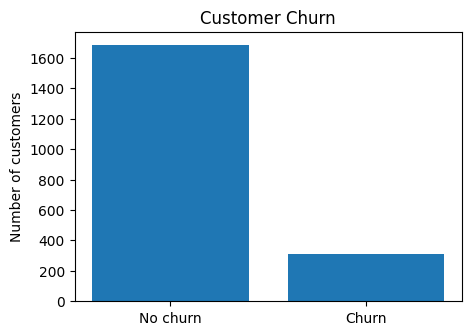

In [44]:
churn_counts = (
    df["churn"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(5, 3.5))

plt.bar(
    ["No churn", "Churn"],
    [churn_counts[0], churn_counts[1]]
)

plt.ylabel("Number of customers")
plt.title("Customer Churn")

plt.show()

In [45]:
feature_summary = pd.DataFrame({
    "Feature": [
        "days_since_last_login",
        "monthly_watch_time",
        "support_complaints",
        "subscription_type",
        "payment_failure",
        "months_subscribed",
        "num_profiles",
        "has_discount",
    ],

    "Type": [
        "numeric",
        "numeric",
        "numeric",
        "categorical",
        "binary",
        "numeric",
        "numeric",
        "binary",
    ],

    "Meaning": [
        "Days since customer last logged in",
        "Hours watched per month",
        "Number of support complaints",
        "Basic, Standard, or Premium plan",
        "Whether a recent payment failed",
        "Length of subscription",
        "Number of user profiles",
        "Whether customer has a discount",
    ],
})

feature_summary

,Feature,Type,Meaning
0,days_since_last_login,numeric,Days since customer last logged in
1,monthly_watch_time,numeric,Hours watched per month
2,support_complaints,numeric,Number of support complaints
3,subscription_type,categorical,"Basic, Standard, or Premium plan"
4,payment_failure,binary,Whether a recent payment failed
5,months_subscribed,numeric,Length of subscription
6,num_profiles,numeric,Number of user profiles
7,has_discount,binary,Whether customer has a discount


Churn is intentionally noisy. The variables influence a customer's probability of churning, but they do not determine the outcome perfectly. Two customers with very similar characteristics can therefore have different outcomes. This gives us a realistic setting in which a large decision tree can begin to memorize random variation in the training data.

In [46]:
X = df.drop(columns="churn")
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

Training observations: 1500
Test observations: 500


# 2. A Four-Leaf Tree: Useful, But Too Simple

## A decision tree with four leaves can only divide the feature space into four final regions. That is not much expressive power.

## A small tree is interpretable, but it may be too crude. If churn depends on several interacting conditions, such as inactivity plus low watch time plus payment failure, a four-leaf tree will miss many cases.

## The four-leaf tree is a good first model because it is readable. Each leaf represents a customer segment. For example:

## - low-risk active customers
## - inactive customers
## - customers with payment problems
## - customers with very low engagement

## But the tree is not expected to perfectly classify the training data. That is not a bug. It is the point. A four-leaf tree underfits when the true pattern is more complex than four simple regions.

## A leaf is not a single prediction rule like “churn” or “no churn.” A leaf stores a class distribution. If a leaf contains 80 no-churn customers and 20 churn customers, then its estimated churn probability is 20 / 100 = 0.20.

## This is why decision trees can produce predicted probabilities, not just class labels.

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, log_loss


# ---------------------------------------------------------
# Encode the categorical feature.
# We fit the encoder on the training data only.
# ---------------------------------------------------------

categorical_features = ["subscription_type"]

numeric_features = [
    column
    for column in X_train.columns
    if column not in categorical_features
]

preprocessor = ColumnTransformer([
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    ),
    (
        "num",
        "passthrough",
        numeric_features
    )
])

X_train_tree = preprocessor.fit_transform(X_train)
X_test_tree = preprocessor.transform(X_test)


# Make the transformed feature names easier to read in the tree.
feature_names = preprocessor.get_feature_names_out()

feature_names = [
    name
    .replace("cat__subscription_type_", "subscription = ")
    .replace("num__", "")
    for name in feature_names
]


# ---------------------------------------------------------
# Helper: obtain the class proportions stored in a node.
#
# This works with sklearn versions in which tree_.value
# contains either counts or proportions.
# ---------------------------------------------------------

def node_class_proportions(tree, node_id):
    values = tree.tree_.value[node_id][0].astype(float)

    if values.sum() == 0:
        return values

    return values / values.sum()


# ---------------------------------------------------------
# Helper: calculate positions for a clean tree diagram.
#
# Leaves are spread evenly from left to right.
# Parent nodes are centered above their children.
# ---------------------------------------------------------

def get_tree_positions(tree):
    children_left = tree.tree_.children_left
    children_right = tree.tree_.children_right

    positions = {}
    next_leaf_x = [0]

    def place_node(node_id, depth=0):
        left = children_left[node_id]
        right = children_right[node_id]

        # Leaf
        if left == -1:
            x = next_leaf_x[0]
            next_leaf_x[0] += 1

        # Internal node
        else:
            left_x = place_node(left, depth + 1)
            right_x = place_node(right, depth + 1)
            x = (left_x + right_x) / 2

        positions[node_id] = (x, -depth)
        return x

    place_node(0)

    return positions


# ---------------------------------------------------------
# Helper: draw a simplified decision tree.
#
# Each node emphasizes only:
#   - split condition
#   - samples
#   - churn rate
#   - predicted class
# ---------------------------------------------------------

def plot_clean_tree(tree, feature_names, title=None):
    positions = get_tree_positions(tree)

    n_leaves = tree.get_n_leaves()
    depth = tree.get_depth()

    # Larger trees get more horizontal and vertical room.
    width = max(14, 1.8 * n_leaves)
    height = max(5.5, 2.0 * (depth + 1))

    fig, ax = plt.subplots(figsize=(width, height))

    children_left = tree.tree_.children_left
    children_right = tree.tree_.children_right

    # Slightly smaller font when many leaves are displayed.
    fontsize = 11 if n_leaves <= 6 else 9

    # Draw connecting lines first so they remain behind the boxes.
    for node_id in range(tree.tree_.node_count):
        left = children_left[node_id]
        right = children_right[node_id]

        if left != -1:
            parent_x, parent_y = positions[node_id]

            for child in [left, right]:
                child_x, child_y = positions[child]

                ax.annotate(
                    "",
                    xy=(child_x, child_y + 0.12),
                    xytext=(parent_x, parent_y - 0.12),
                    arrowprops=dict(
                        arrowstyle="-",
                        linewidth=1.3
                    ),
                    zorder=1
                )

    # Draw node boxes.
    for node_id in range(tree.tree_.node_count):

        x, y = positions[node_id]

        proportions = node_class_proportions(tree, node_id)
        churn_rate = proportions[1]

        predicted_class = (
            "Churn"
            if churn_rate >= 0.50
            else "No churn"
        )

        samples = tree.tree_.n_node_samples[node_id]

        left = children_left[node_id]

        # Leaf node
        if left == -1:
            first_line = "LEAF"

        # Split node
        else:
            feature_number = tree.tree_.feature[node_id]
            threshold = tree.tree_.threshold[node_id]

            feature = feature_names[feature_number]

            # One-hot encoded categorical variables split at 0.5.
            if feature.startswith("subscription = "):
                first_line = f"{feature} ≤ {threshold:.1f}"
            else:
                first_line = f"{feature} ≤ {threshold:.1f}"

        label = (
            f"{first_line}\n"
            f"samples = {samples}\n"
            f"churn rate = {churn_rate:.2f}\n"
            f"predict: {predicted_class}"
        )

        ax.text(
            x,
            y,
            label,
            ha="center",
            va="center",
            fontsize=fontsize,
            bbox=dict(
                boxstyle="round,pad=0.45",
                facecolor="white",
                edgecolor="black",
                linewidth=1.2
            ),
            zorder=2
        )

    xs = [x for x, y in positions.values()]
    ys = [y for x, y in positions.values()]

    # Extra whitespace around the tree prevents boxes from clipping.
    ax.set_xlim(min(xs) - 0.8, max(xs) + 0.8)
    ax.set_ylim(min(ys) - 0.65, 0.75)

    ax.axis("off")

    if title is not None:
        ax.set_title(
            title,
            fontsize=16,
            pad=20
        )

    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------
# Helper: make one row per leaf.
# ---------------------------------------------------------

def make_leaf_summary(tree, X_data, y_data):

    leaf_ids = tree.apply(X_data)

    leaf_df = pd.DataFrame({
        "leaf_id": leaf_ids,
        "churn": np.asarray(y_data)
    })

    summary = (
        leaf_df
        .groupby("leaf_id")
        .agg(
            training_samples=("churn", "size"),
            no_churn_count=("churn", lambda x: (x == 0).sum()),
            churn_count=("churn", lambda x: (x == 1).sum()),
            churn_rate=("churn", "mean")
        )
        .reset_index()
    )

    summary["predicted_class"] = np.where(
        summary["churn_rate"] >= 0.5,
        "Churn",
        "No churn"
    )

    summary["churn_rate"] = summary["churn_rate"].round(3)

    return summary


# ---------------------------------------------------------
# Helper: compact performance table.
# ---------------------------------------------------------

def make_performance_table(tree):

    train_predictions = tree.predict(X_train_tree)
    test_predictions = tree.predict(X_test_tree)

    train_probabilities = tree.predict_proba(X_train_tree)
    test_probabilities = tree.predict_proba(X_test_tree)

    performance = pd.DataFrame({
        "train accuracy": [
            accuracy_score(y_train, train_predictions)
        ],
        "test accuracy": [
            accuracy_score(y_test, test_predictions)
        ],
        "train log loss": [
            log_loss(y_train, train_probabilities)
        ],
        "test log loss": [
            log_loss(y_test, test_probabilities)
        ],
        "leaves": [
            tree.get_n_leaves()
        ],
        "depth": [
            tree.get_depth()
        ]
    })

    return performance.round(3)

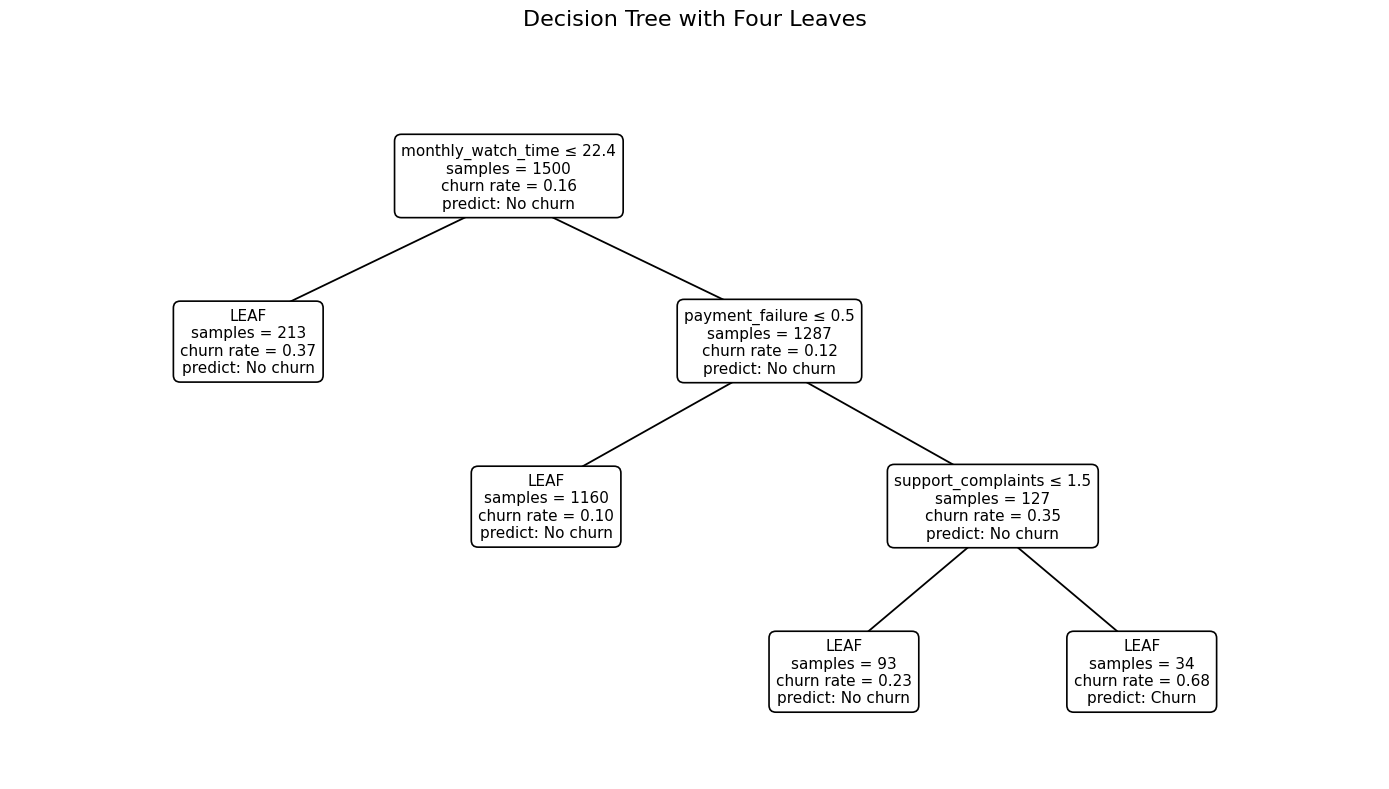

,leaf_id,training_samples,no_churn_count,churn_count,churn_rate,predicted_class
0,1,213,134,79,0.371,No churn
1,3,1160,1048,112,0.097,No churn
2,5,93,72,21,0.226,No churn
3,6,34,11,23,0.676,Churn


,train accuracy,test accuracy,train log loss,test log loss,leaves,depth
0,0.851,0.848,0.387,0.412,4,3


In [48]:
four_leaf_tree = DecisionTreeClassifier(
    max_leaf_nodes=4,
    random_state=42
)

four_leaf_tree.fit(
    X_train_tree,
    y_train
)


# 1. TREE
plot_clean_tree(
    four_leaf_tree,
    feature_names,
    title="Decision Tree with Four Leaves"
)


# 2. LEAF SUMMARY
leaf_summary = make_leaf_summary(
    four_leaf_tree,
    X_train_tree,
    y_train
)

display(leaf_summary)


# 3. PERFORMANCE
performance = make_performance_table(
    four_leaf_tree
)

display(performance)

In [49]:
import ipywidgets as widgets
from IPython.display import display, clear_output


leaf_slider = widgets.IntSlider(
    value=4,
    min=2,
    max=12,
    step=1,
    description="Max leaves:",
    continuous_update=False,
    style={"description_width": "80px"},
    layout=widgets.Layout(width="500px")
)

interactive_output = widgets.Output()


def update_tree(change=None):

    max_leaves = leaf_slider.value

    tree = DecisionTreeClassifier(
        max_leaf_nodes=max_leaves,
        random_state=42
    )

    tree.fit(
        X_train_tree,
        y_train
    )

    train_probabilities = tree.predict_proba(X_train_tree)
    test_probabilities = tree.predict_proba(X_test_tree)

    test_predictions = tree.predict(X_test_tree)

    metrics = pd.DataFrame({
        "max_leaf_nodes": [max_leaves],
        "actual leaves": [tree.get_n_leaves()],
        "train log loss": [
            log_loss(y_train, train_probabilities)
        ],
        "test log loss": [
            log_loss(y_test, test_probabilities)
        ],
        "test accuracy": [
            accuracy_score(y_test, test_predictions)
        ]
    }).round(3)

    with interactive_output:

        clear_output(wait=True)

        plot_clean_tree(
            tree,
            feature_names,
            title=f"Decision Tree: max_leaf_nodes = {max_leaves}"
        )

        display(metrics)


leaf_slider.observe(
    update_tree,
    names="value"
)

display(leaf_slider, interactive_output)

update_tree()

IntSlider(value=4, continuous_update=False, description='Max leaves:', layout=Layout(width='500px'), max=12, m…

Output()

# 3. Gini, Entropy, and the Meaning of a Good Split

## Decision trees grow by asking: “Which split makes the child nodes less mixed?”

## If a node contains half churn and half no churn, we are highly uncertain. If a node contains almost all no-churn customers, we are less uncertain. Gini impurity and entropy both measure this kind of mixing.

## For binary classification, if `p` is the proportion of churn customers in a node:

## Gini impurity:

## `Gini = 1 - p² - (1 - p)²`

## Entropy:

## `Entropy = -p log₂(p) - (1 - p) log₂(1 - p)`

## Both are highest near `p = 0.5`. Both are lowest near `p = 0` or `p = 1`.

## The tree does not only care whether one child is pure. It cares about the weighted average impurity of both children. A split that creates one tiny pure node and one huge mixed node may not be very useful.

## Information gain is the reduction in impurity:

## `Information Gain = Parent Impurity - Weighted Child Impurity`

## The best split is the split with the largest impurity reduction among the candidate splits considered.

## Gini and entropy are not evaluation metrics in the same way accuracy, AUC, or log loss are. They are training criteria used by the tree-building algorithm. We can train with Gini and evaluate with log loss. Those are different roles.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output


# ============================================================
# DEMO PLAN 3
# Gini, Entropy, and the Meaning of a Good Split
# ============================================================


# ------------------------------------------------------------
# Impurity functions
# ------------------------------------------------------------

def gini(p):
    return 1 - p**2 - (1 - p)**2


def entropy(p):
    p = np.asarray(p, dtype=float)

    # Entropy is defined as 0 at p = 0 and p = 1.
    with np.errstate(divide="ignore", invalid="ignore"):
        result = -(
            np.where(p > 0, p * np.log2(p), 0)
            +
            np.where(p < 1, (1 - p) * np.log2(1 - p), 0)
        )

    return result


# ============================================================
# PART 1
# Interactive impurity curves
# ============================================================

p_slider = widgets.FloatSlider(
    value=0.50,
    min=0.00,
    max=1.00,
    step=0.01,
    description="p(churn):",
    continuous_update=True,
    readout_format=".2f",
    style={"description_width": "80px"},
    layout=widgets.Layout(width="500px")
)

impurity_output = widgets.Output()


def update_impurity(change=None):

    p = p_slider.value

    p_values = np.linspace(0, 1, 501)

    gini_values = gini(p_values)
    entropy_values = entropy(p_values)

    current_gini = float(gini(p))
    current_entropy = float(entropy(p))

    table = pd.DataFrame({
        "p(churn)": [p],
        "p(no churn)": [1 - p],
        "Gini": [current_gini],
        "Entropy": [current_entropy]
    }).round(3)

    with impurity_output:

        clear_output(wait=True)

        fig, ax = plt.subplots(figsize=(9, 5))

        ax.plot(
            p_values,
            gini_values,
            linewidth=2.5,
            label="Gini impurity"
        )

        ax.plot(
            p_values,
            entropy_values,
            linewidth=2.5,
            label="Entropy"
        )

        # Current p(churn)
        ax.axvline(
            p,
            linestyle="--",
            linewidth=1.5
        )

        ax.scatter(
            [p],
            [current_gini],
            s=90,
            zorder=5
        )

        ax.scatter(
            [p],
            [current_entropy],
            s=90,
            zorder=5
        )

        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.05)

        ax.set_xlabel(
            "p(churn)",
            fontsize=12
        )

        ax.set_ylabel(
            "Impurity",
            fontsize=12
        )

        ax.set_title(
            "Gini and Entropy Measure How Mixed a Node Is",
            fontsize=15,
            pad=15
        )

        ax.legend(
            loc="upper right",
            fontsize=11
        )

        ax.grid(
            alpha=0.20
        )

        plt.tight_layout()
        plt.show()

        display(table)


p_slider.observe(
    update_impurity,
    names="value"
)


display(
    widgets.HTML(
        "<h3>1. How impurity changes with p(churn)</h3>"
    ),
    p_slider,
    impurity_output
)

update_impurity()


# ============================================================
# PART 2
# Interactive candidate split
# ============================================================

split_feature = "days_since_last_login"

feature_values = X_train[split_feature].to_numpy()
target_values = np.asarray(y_train)

# Use a sensible slider range based on the training data.
threshold_min = int(np.floor(np.percentile(feature_values, 5)))
threshold_max = int(np.ceil(np.percentile(feature_values, 95)))

split_slider = widgets.IntSlider(
    value=18,
    min=threshold_min,
    max=threshold_max,
    step=1,
    description="Threshold:",
    continuous_update=True,
    style={"description_width": "80px"},
    layout=widgets.Layout(width="500px")
)

split_output = widgets.Output()


def node_stats(y):

    n = len(y)

    if n == 0:
        return {
            "n": 0,
            "churn": 0,
            "no_churn": 0,
            "rate": 0,
            "entropy": 0
        }

    churn_count = int(np.sum(y == 1))
    no_churn_count = int(np.sum(y == 0))

    rate = churn_count / n

    return {
        "n": n,
        "churn": churn_count,
        "no_churn": no_churn_count,
        "rate": rate,
        "entropy": float(entropy(rate))
    }


def draw_node(
    ax,
    x,
    y,
    width,
    height,
    stats,
    title
):

    # Higher churn rate -> stronger shading.
    # We leave the color choice to matplotlib.
    intensity = stats["rate"]

    rectangle = plt.Rectangle(
        (x, y),
        width,
        height,
        alpha=0.18 + 0.62 * intensity,
        edgecolor="black",
        linewidth=1.5
    )

    ax.add_patch(rectangle)

    label = (
        f"{title}\n"
        f"n = {stats['n']}\n"
        f"churn = {stats['churn']}\n"
        f"no churn = {stats['no_churn']}\n"
        f"churn rate = {stats['rate']:.1%}"
    )

    ax.text(
        x + width / 2,
        y + height / 2,
        label,
        ha="center",
        va="center",
        fontsize=11
    )


def update_split(change=None):

    threshold = split_slider.value

    left_mask = feature_values <= threshold
    right_mask = feature_values > threshold

    parent = node_stats(target_values)

    left = node_stats(
        target_values[left_mask]
    )

    right = node_stats(
        target_values[right_mask]
    )

    weighted_child_entropy = (
        left["n"] / parent["n"] * left["entropy"]
        +
        right["n"] / parent["n"] * right["entropy"]
    )

    information_gain = (
        parent["entropy"]
        -
        weighted_child_entropy
    )

    metric_table = pd.DataFrame({
        "Quantity": [
            "Parent entropy",
            "Left entropy",
            "Right entropy",
            "Weighted child entropy",
            "Information gain"
        ],
        "Value": [
            parent["entropy"],
            left["entropy"],
            right["entropy"],
            weighted_child_entropy,
            information_gain
        ]
    })

    metric_table["Value"] = (
        metric_table["Value"].round(4)
    )

    with split_output:

        clear_output(wait=True)

        # ----------------------------------------------------
        # Visual node diagram
        # ----------------------------------------------------

        fig, ax = plt.subplots(
            figsize=(11, 6.5)
        )

        # Parent
        draw_node(
            ax,
            x=3.5,
            y=3.8,
            width=3.0,
            height=1.5,
            stats=parent,
            title="Parent node"
        )

        # Left child
        draw_node(
            ax,
            x=0.7,
            y=0.5,
            width=3.7,
            height=1.7,
            stats=left,
            title=f"{split_feature} ≤ {threshold}"
        )

        # Right child
        draw_node(
            ax,
            x=5.6,
            y=0.5,
            width=3.7,
            height=1.7,
            stats=right,
            title=f"{split_feature} > {threshold}"
        )

        # Connecting lines
        ax.plot(
            [5.0, 2.55],
            [3.8, 2.2],
            linewidth=1.5
        )

        ax.plot(
            [5.0, 7.45],
            [3.8, 2.2],
            linewidth=1.5
        )

        # Information gain annotation
        ax.text(
            5.0,
            2.75,
            (
                f"Weighted child entropy = "
                f"{weighted_child_entropy:.3f}\n"
                f"Information gain = "
                f"{information_gain:.3f}"
            ),
            ha="center",
            va="center",
            fontsize=12,
            bbox=dict(
                boxstyle="round,pad=0.5",
                facecolor="white",
                edgecolor="black"
            )
        )

        ax.set_xlim(0, 10)
        ax.set_ylim(0, 5.8)

        ax.set_title(
            "Does This Split Make the Child Nodes Less Mixed?",
            fontsize=15,
            pad=16
        )

        ax.axis("off")

        plt.tight_layout()
        plt.show()

        display(metric_table)


split_slider.observe(
    update_split,
    names="value"
)


display(
    widgets.HTML(
        "<br><h3>2. Information gain for one candidate split</h3>"
        "<b>Move the threshold and watch the two child nodes change.</b>"
    ),
    split_slider,
    split_output
)

update_split()

HTML(value='<h3>1. How impurity changes with p(churn)</h3>')

FloatSlider(value=0.5, description='p(churn):', layout=Layout(width='500px'), max=1.0, step=0.01, style=Slider…

Output()

HTML(value='<br><h3>2. Information gain for one candidate split</h3><b>Move the threshold and watch the two ch…

IntSlider(value=18, description='Threshold:', layout=Layout(width='500px'), max=38, min=2, style=SliderStyle(d…

Output()

In [53]:
PE = -(0.157 * np.log2(0.157) + 0.843 * np.log2(0.843))
WCE = (994 / 1500) * -(0.121 * np.log2(0.121) + 0.879 * np.log2(0.879)) + (506 / 1500) * -(0.227 * np.log2(0.227) + 0.773 * np.log2(0.773))
PE - WCE

np.float64(0.013721352749276772)

In [40]:
# for 18
PE = (np.log2(0.157) * 0.157 + np.log2(0.843) * 0.843)
WCE = (994 / 1500) * (np.log2(0.121) * 0.121 + np.log2(0.879) * 0.879) + (506 / 1500) * (np.log2(0.227) * 0.227 + np.log2(0.773) * 0.773)
PE, WCE, PE - WCE

(np.float64(-0.6270840510319262),
 np.float64(-0.6133626982826494),
 np.float64(-0.013721352749276772))

# 4. Log Loss: Accuracy Is Not Enough

## Accuracy evaluates hard predictions. Log loss evaluates predicted probabilities.

## This distinction matters because decision trees produce probabilities from leaf proportions. Suppose a leaf contains 90 no-churn customers and 10 churn customers. The tree predicts:

## - `P(churn) = 0.10`
## - `P(no churn) = 0.90`

## If the true label is no churn, that is a confident and correct probability. If the true label is churn, the model gets penalized heavily because it assigned only 0.10 probability to the event that happened.

## Binary log loss for one observation is:

## `Loss = -[y log(p) + (1 - y) log(1 - p)]`

## where:

## - `y = 1` means churn
## - `y = 0` means no churn
## - `p` is the predicted probability of churn

## For a dataset, we average this loss across all observations.

## Why use log loss here?

## Accuracy can hide bad probability estimates. A model that predicts churn probability 0.49 for every actual churn case may classify them all as no churn, but it is very different from a model that predicts 0.01. Log loss sees that difference.

## Also, in business settings, predicted probabilities are often more useful than hard labels. A streaming company may not need a yes/no churn prediction; it may need a ranked list of customers by churn risk.

,customer,true_label,predicted_churn_probability,predicted_class,individual_log_loss
0,A,Churn,0.9,Churn,0.105
1,B,Churn,0.1,No churn,2.303
2,C,No churn,0.1,No churn,0.105
3,D,No churn,0.9,Churn,2.303


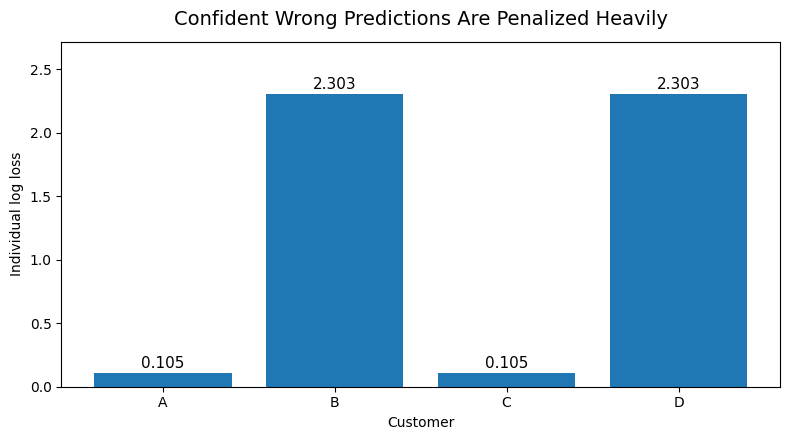

HTML(value='<h3>Four-leaf tree: predicted probabilities</h3><p>A customer receives the churn probability store…

,predicted churn probability,training customers
0,0.097,1160
1,0.226,93
2,0.371,213
3,0.676,34


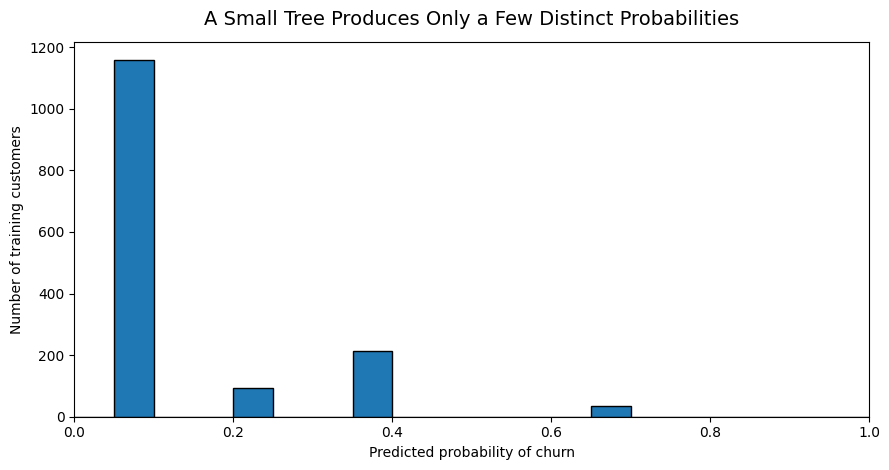

,Dataset,Log loss
0,Training,0.387
1,Test,0.412


HTML(value='<h3>Interactive: What happens as predicted probability changes?</h3>')

FloatSlider(value=0.5, description='Predicted p:', layout=Layout(width='520px'), max=0.99, min=0.01, step=0.01…

Output()

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output
from sklearn.metrics import log_loss


# ============================================================
# DEMO PLAN 4
# Probability Quality and Log Loss
# ============================================================


# ------------------------------------------------------------
# Helper: individual binary log loss
# ------------------------------------------------------------

def individual_log_loss(y, p):
    # Clip probabilities so log(0) never occurs.
    p = np.clip(p, 1e-15, 1 - 1e-15)

    return -(
        y * np.log(p)
        +
        (1 - y) * np.log(1 - p)
    )


# ============================================================
# PART 1
# Four hypothetical customers
# ============================================================

customer_demo = pd.DataFrame({
    "customer": ["A", "B", "C", "D"],
    "true_label": [1, 1, 0, 0],
    "predicted_churn_probability": [0.90, 0.10, 0.10, 0.90]
})

customer_demo["predicted_class"] = np.where(
    customer_demo["predicted_churn_probability"] >= 0.50,
    "Churn",
    "No churn"
)

customer_demo["individual_log_loss"] = [
    individual_log_loss(y, p)
    for y, p in zip(
        customer_demo["true_label"],
        customer_demo["predicted_churn_probability"]
    )
]

customer_demo["true_label"] = customer_demo["true_label"].map({
    0: "No churn",
    1: "Churn"
})

customer_demo["individual_log_loss"] = (
    customer_demo["individual_log_loss"].round(3)
)


display(
    customer_demo[
        [
            "customer",
            "true_label",
            "predicted_churn_probability",
            "predicted_class",
            "individual_log_loss"
        ]
    ]
)


# ------------------------------------------------------------
# Bar chart: individual log loss
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.bar(
    customer_demo["customer"],
    customer_demo["individual_log_loss"]
)

ax.set_xlabel("Customer")
ax.set_ylabel("Individual log loss")

ax.set_title(
    "Confident Wrong Predictions Are Penalized Heavily",
    fontsize=14,
    pad=12
)

for i, loss in enumerate(customer_demo["individual_log_loss"]):
    ax.text(
        i,
        loss + 0.04,
        f"{loss:.3f}",
        ha="center",
        fontsize=11
    )

ax.set_ylim(
    0,
    customer_demo["individual_log_loss"].max() * 1.18
)

plt.tight_layout()
plt.show()


# ============================================================
# PART 2
# Connect log loss to the four-leaf decision tree
# ============================================================

train_probabilities = four_leaf_tree.predict_proba(
    X_train_tree
)[:, 1]

test_probabilities = four_leaf_tree.predict_proba(
    X_test_tree
)[:, 1]


# Show the distinct probability values produced by the tree.
unique_train_probabilities, probability_counts = np.unique(
    np.round(train_probabilities, 6),
    return_counts=True
)

probability_table = pd.DataFrame({
    "predicted churn probability": unique_train_probabilities,
    "training customers": probability_counts
})

probability_table[
    "predicted churn probability"
] = probability_table[
    "predicted churn probability"
].round(3)


display(
    widgets.HTML(
        "<h3>Four-leaf tree: predicted probabilities</h3>"
        "<p>A customer receives the churn probability stored in the "
        "leaf where that customer ends up.</p>"
    )
)

display(probability_table)


# ------------------------------------------------------------
# Histogram of tree probabilities
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 4.8))

ax.hist(
    train_probabilities,
    bins=np.linspace(0, 1, 21),
    edgecolor="black"
)

ax.set_xlim(0, 1)

ax.set_xlabel(
    "Predicted probability of churn"
)

ax.set_ylabel(
    "Number of training customers"
)

ax.set_title(
    "A Small Tree Produces Only a Few Distinct Probabilities",
    fontsize=14,
    pad=12
)

plt.tight_layout()
plt.show()


# Compact tree-level performance
tree_log_loss_table = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "Log loss": [
        log_loss(y_train, train_probabilities),
        log_loss(y_test, test_probabilities)
    ]
})

tree_log_loss_table["Log loss"] = (
    tree_log_loss_table["Log loss"].round(3)
)

display(tree_log_loss_table)


# ============================================================
# PART 3
# Interactive log-loss curves
# ============================================================

probability_slider = widgets.FloatSlider(
    value=0.50,
    min=0.01,
    max=0.99,
    step=0.01,
    description="Predicted p:",
    continuous_update=True,
    readout_format=".2f",
    style={"description_width": "100px"},
    layout=widgets.Layout(width="520px")
)

logloss_output = widgets.Output()


def update_logloss_curves(change=None):

    p = probability_slider.value

    p_values = np.linspace(
        0.01,
        0.99,
        500
    )

    loss_if_churn = -np.log(p_values)
    loss_if_no_churn = -np.log(1 - p_values)

    current_loss_churn = individual_log_loss(
        1,
        p
    )

    current_loss_no_churn = individual_log_loss(
        0,
        p
    )

    live_table = pd.DataFrame({
        "If true outcome is...": [
            "Churn (y = 1)",
            "No churn (y = 0)"
        ],
        "Predicted p(churn)": [
            p,
            p
        ],
        "Log loss": [
            current_loss_churn,
            current_loss_no_churn
        ]
    })

    live_table[
        "Predicted p(churn)"
    ] = live_table[
        "Predicted p(churn)"
    ].round(2)

    live_table["Log loss"] = (
        live_table["Log loss"].round(3)
    )

    with logloss_output:

        clear_output(wait=True)

        fig, ax = plt.subplots(
            figsize=(9, 5)
        )

        ax.plot(
            p_values,
            loss_if_churn,
            linewidth=2.5,
            label="True outcome: churn"
        )

        ax.plot(
            p_values,
            loss_if_no_churn,
            linewidth=2.5,
            label="True outcome: no churn"
        )

        ax.axvline(
            p,
            linestyle="--",
            linewidth=1.5
        )

        ax.scatter(
            [p],
            [current_loss_churn],
            s=90,
            zorder=5
        )

        ax.scatter(
            [p],
            [current_loss_no_churn],
            s=90,
            zorder=5
        )

        ax.set_xlim(0, 1)
        ax.set_ylim(0, 4.8)

        ax.set_xlabel(
            "Predicted probability of churn"
        )

        ax.set_ylabel(
            "Log loss"
        )

        ax.set_title(
            "Log Loss Punishes Confident Mistakes",
            fontsize=14,
            pad=12
        )

        ax.legend(
            loc="upper center"
        )

        ax.grid(
            alpha=0.20
        )

        plt.tight_layout()
        plt.show()

        display(live_table)


probability_slider.observe(
    update_logloss_curves,
    names="value"
)


display(
    widgets.HTML(
        "<h3>Interactive: What happens as predicted probability changes?</h3>"
    ),
    probability_slider,
    logloss_output
)

update_logloss_curves()

# 5. Unlimited Leaves: Memorization Is Not Learning

## A fully grown decision tree can keep splitting until many leaves are tiny. In the extreme case, leaves may contain only one training example. If each leaf contains one training example, the tree can often predict the training data perfectly.

## That sounds good until we remember that the training labels contain noise.

## A fully grown tree may learn real patterns, but it may also learn accidental quirks:

## - one unusual customer who churned despite high engagement
## - one customer who did not churn despite many warning signs
## - random variation in the training sample
## - measurement noise
## - one-off combinations of features that will not repeat

## This is why training performance alone is dangerous. The unlimited tree may get nearly perfect training accuracy and near-zero training log loss while performing worse on new customers.

## The important distinction:

## Underfitting: the model is too simple to capture the real pattern.

## Overfitting: the model is complex enough to capture the real pattern plus random noise.

## Generalization: the model performs well on data it did not train on.

,model,depth,leaves,train accuracy,test accuracy,train log loss,test log loss
0,Four-leaf tree,3,4,0.851,0.848,0.387,0.412
1,Unlimited tree,18,248,1.000,0.750,0.000,9.011


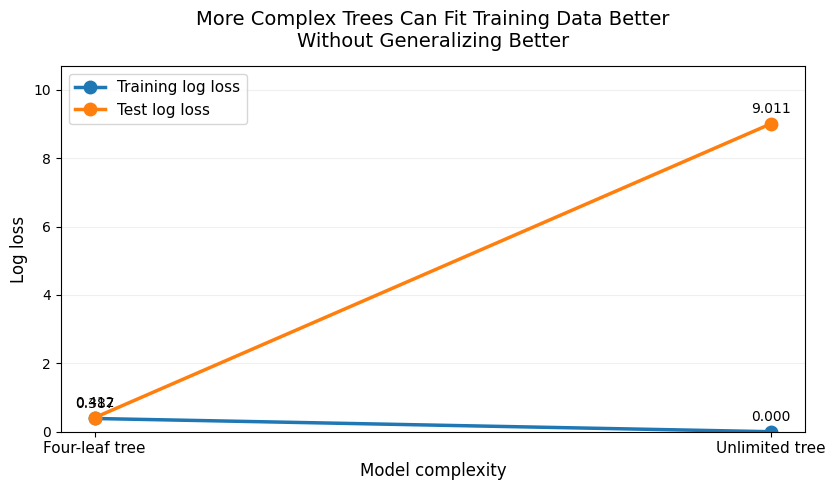

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, log_loss


# ============================================================
# DEMO PLAN 5
# Four Leaves Versus Unlimited Leaves
# ============================================================


# ------------------------------------------------------------
# Fit the two trees
# ------------------------------------------------------------

small_tree = DecisionTreeClassifier(
    max_leaf_nodes=4,
    random_state=42
)

unlimited_tree = DecisionTreeClassifier(
    max_depth=None,
    max_leaf_nodes=None,
    random_state=42
)

small_tree.fit(
    X_train_tree,
    y_train
)

unlimited_tree.fit(
    X_train_tree,
    y_train
)


# ------------------------------------------------------------
# Helper: calculate performance
# ------------------------------------------------------------

def tree_performance(model, model_name):

    train_pred = model.predict(X_train_tree)
    test_pred = model.predict(X_test_tree)

    train_prob = model.predict_proba(X_train_tree)[:, 1]
    test_prob = model.predict_proba(X_test_tree)[:, 1]

    return {
        "model": model_name,
        "depth": model.get_depth(),
        "leaves": model.get_n_leaves(),
        "train accuracy": accuracy_score(
            y_train,
            train_pred
        ),
        "test accuracy": accuracy_score(
            y_test,
            test_pred
        ),
        "train log loss": log_loss(
            y_train,
            train_prob
        ),
        "test log loss": log_loss(
            y_test,
            test_prob
        )
    }


# ------------------------------------------------------------
# Compact comparison table
# ------------------------------------------------------------

comparison = pd.DataFrame([
    tree_performance(
        small_tree,
        "Four-leaf tree"
    ),
    tree_performance(
        unlimited_tree,
        "Unlimited tree"
    )
])

numeric_columns = [
    "train accuracy",
    "test accuracy",
    "train log loss",
    "test log loss"
]

comparison[numeric_columns] = (
    comparison[numeric_columns].round(3)
)

display(comparison)


# ------------------------------------------------------------
# Simple visual:
# training loss versus test loss
# ------------------------------------------------------------

complexity_labels = [
    "Four-leaf tree",
    "Unlimited tree"
]

x = np.arange(len(complexity_labels))

train_losses = comparison[
    "train log loss"
].to_numpy()

test_losses = comparison[
    "test log loss"
].to_numpy()


fig, ax = plt.subplots(
    figsize=(8.5, 5)
)

ax.plot(
    x,
    train_losses,
    marker="o",
    markersize=9,
    linewidth=2.5,
    label="Training log loss"
)

ax.plot(
    x,
    test_losses,
    marker="o",
    markersize=9,
    linewidth=2.5,
    label="Test log loss"
)

ax.set_xticks(x)
ax.set_xticklabels(
    complexity_labels,
    fontsize=11
)

ax.set_ylabel(
    "Log loss",
    fontsize=12
)

ax.set_xlabel(
    "Model complexity",
    fontsize=12
)

ax.set_title(
    "More Complex Trees Can Fit Training Data Better\nWithout Generalizing Better",
    fontsize=14,
    pad=14
)

ax.legend(
    fontsize=11
)

ax.grid(
    axis="y",
    alpha=0.20
)


# ------------------------------------------------------------
# Label all four points clearly
# ------------------------------------------------------------

vertical_offset = max(
    0.03,
    0.025 * max(test_losses.max(), 1)
)

for i in range(len(x)):

    ax.text(
        x[i],
        train_losses[i] + vertical_offset,
        f"{train_losses[i]:.3f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

    ax.text(
        x[i],
        test_losses[i] + vertical_offset,
        f"{test_losses[i]:.3f}",
        ha="center",
        va="bottom",
        fontsize=10
    )


# Add enough headroom that labels do not collide with the title.
current_top = max(
    train_losses.max(),
    test_losses.max()
)

ax.set_ylim(
    0,
    current_top * 1.18 + 0.05
)

plt.tight_layout()
plt.show()

# 6. Choosing Tree Size: The Bias-Variance Tradeoff in Practice

## Tree complexity is controlled by hyperparameters. The most important ones are:

## - `max_depth`
## - `max_leaf_nodes`
## - `min_samples_split`
## - `min_samples_leaf`
## - `ccp_alpha`

## These are not learned from the data in the same way split thresholds are learned. They are hyperparameters: choices we set before or during model selection.

## Smaller trees tend to have higher bias and lower variance. They may miss real structure.

## Larger trees tend to have lower bias and higher variance. They may fit training noise.

## The practical question is not “What tree has the best training score?” The practical question is:

## Which level of complexity gives the best validation or cross-validation performance?

## A good model selection workflow separates three roles:

## - Training data: used to fit model parameters.
## - Validation or cross-validation data: used to choose hyperparameters.
## - Holdout test data: used once at the end to estimate final performance.

## If we repeatedly use the test set to make modeling decisions, it stops being an honest test set.

,max_depth,leaves,train_log_loss,test_log_loss,train_accuracy,test_accuracy
0,1,2,0.411,0.422,0.844,0.843
1,2,4,0.386,0.415,0.846,0.823
2,3,8,0.365,0.423,0.862,0.850
3,4,16,0.337,0.441,0.874,0.832
4,5,31,0.306,1.103,0.889,0.825
5,8,98,0.196,3.666,0.928,0.803
6,12,181,0.074,7.576,0.971,0.767
7,None,236,0.000,9.311,1.000,0.742


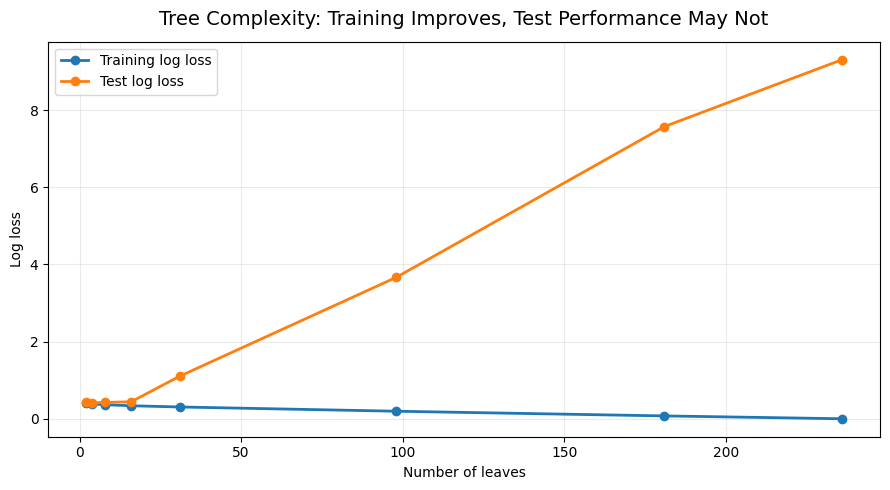

Best max_depth by test log loss: 2
Number of leaves: 4
Test log loss: 0.415


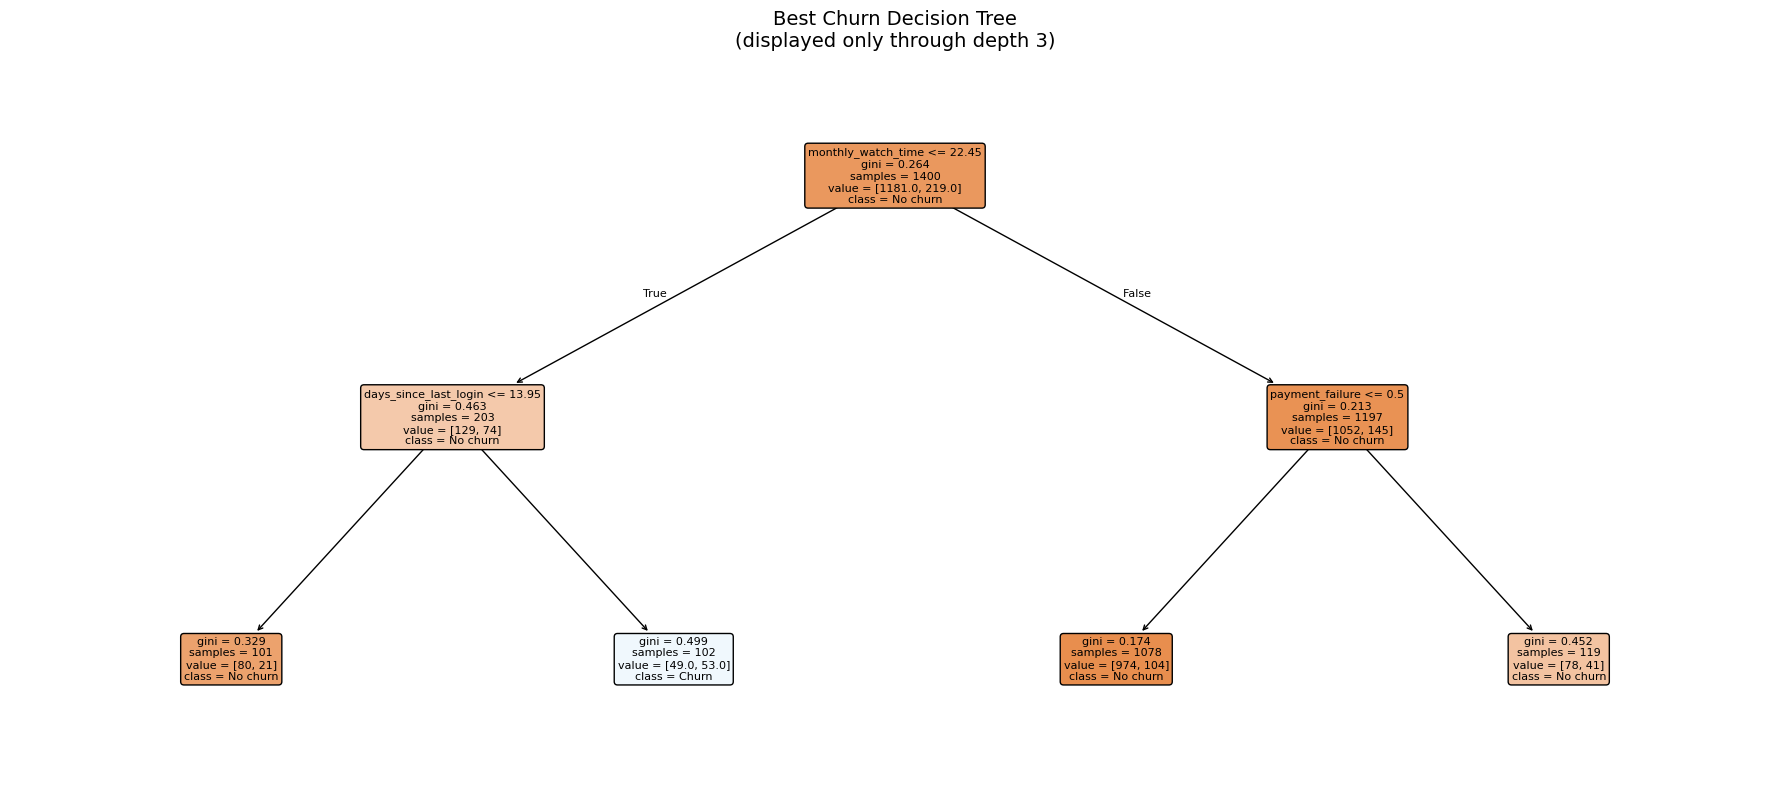

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import log_loss, accuracy_score


# ============================================================
# CHURN DATASET DECISION TREE DEMO
# A simple example of underfitting and overfitting
#
# Assumes the churn dataset "df" was created above.
# ============================================================

RANDOM_STATE = 42


# ------------------------------------------------------------
# 1. Prepare the churn dataset
# ------------------------------------------------------------

X = df.drop(
    columns="churn"
)

y = df["churn"]


# Convert the categorical subscription_type variable
# into numeric dummy variables.
X = pd.get_dummies(
    X,
    columns=["subscription_type"],
    drop_first=False
)


(
    X_train,
    X_test,
    y_train,
    y_test
) = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)


# ------------------------------------------------------------
# 2. Fit trees of increasing complexity
# ------------------------------------------------------------

depth_values = [1, 2, 3, 4, 5, 8, 12, None]

tree_results = []

for depth in depth_values:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=RANDOM_STATE
    )

    model.fit(
        X_train,
        y_train
    )

    train_prob = model.predict_proba(
        X_train
    )

    test_prob = model.predict_proba(
        X_test
    )

    tree_results.append({
        "max_depth": "None" if depth is None else str(depth),
        "leaves": model.get_n_leaves(),
        "train_log_loss": log_loss(
            y_train,
            train_prob
        ),
        "test_log_loss": log_loss(
            y_test,
            test_prob
        ),
        "train_accuracy": accuracy_score(
            y_train,
            model.predict(X_train)
        ),
        "test_accuracy": accuracy_score(
            y_test,
            model.predict(X_test)
        )
    })


tree_results_df = pd.DataFrame(
    tree_results
)

display(
    tree_results_df.round(3)
)


# ------------------------------------------------------------
# 3. Complexity curve
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    tree_results_df["leaves"],
    tree_results_df["train_log_loss"],
    marker="o",
    linewidth=2,
    label="Training log loss"
)

ax.plot(
    tree_results_df["leaves"],
    tree_results_df["test_log_loss"],
    marker="o",
    linewidth=2,
    label="Test log loss"
)

ax.set_xlabel(
    "Number of leaves"
)

ax.set_ylabel(
    "Log loss"
)

ax.set_title(
    "Tree Complexity: Training Improves, Test Performance May Not",
    fontsize=14,
    pad=12
)

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. Show the best tree by test log loss
# ------------------------------------------------------------

best_index = (
    tree_results_df["test_log_loss"].idxmin()
)

best_depth_label = (
    tree_results_df.loc[
        best_index,
        "max_depth"
    ]
)

best_depth = (
    None
    if best_depth_label == "None"
    else int(best_depth_label)
)

best_tree = DecisionTreeClassifier(
    max_depth=best_depth,
    random_state=RANDOM_STATE
)

best_tree.fit(
    X_train,
    y_train
)

print(
    f"Best max_depth by test log loss: {best_depth_label}"
)

print(
    f"Number of leaves: {best_tree.get_n_leaves()}"
)

print(
    f"Test log loss: "
    f"{tree_results_df.loc[best_index, 'test_log_loss']:.3f}"
)


plt.figure(
    figsize=(18, 8)
)

plot_tree(
    best_tree,
    filled=True,
    rounded=True,
    feature_names=X.columns,
    class_names=["No churn", "Churn"],
    max_depth=3,
    fontsize=8
)

plt.title(
    "Best Churn Decision Tree\n(displayed only through depth 3)",
    fontsize=14
)

plt.tight_layout()
plt.show()

# 7. GridSearchCV: Systematic Hyperparameter Selection

## Manual tuning is useful for intuition, but real modeling usually uses cross-validation.

## Cross-validation repeatedly splits the training data into fitting folds and validation folds. Each hyperparameter setting gets evaluated several times, and we compare average validation performance.

## `GridSearchCV` automates this:

## 1. Choose a model class.
## 2. Define a grid of hyperparameter values.
## 3. Fit each combination using cross-validation.
## 4. Select the combination with the best average validation score.
## 5. Refit the best model on the full training set.
## 6. Evaluate once on the holdout test set.

## A decision-tree grid might include:

## - `criterion`: `gini`, `entropy`
## - `max_depth`: small, medium, unrestricted
## - `min_samples_leaf`: 1, 5, 10, 25, 50
## - `max_leaf_nodes`: 4, 8, 16, 32, unrestricted
## - `ccp_alpha`: pruning strength

## Use log loss as the selection metric if probability quality matters. Use F1, recall, precision, ROC AUC, or PR AUC if the business problem calls for a different tradeoff.

## For churn, accuracy can be misleading because churn may be the minority class. A model can get decent accuracy by predicting “no churn” most of the time.

Best hyperparameters:


,ccp_alpha,criterion,max_depth,min_samples_leaf
0,0.001,gini,4,50


Best mean CV log loss: 0.380

Final performance:


,dataset,accuracy,log loss
0,Training,0.847,0.367
1,Holdout test,0.818,0.414



Top 10 hyperparameter settings:


,param_criterion,param_max_depth,param_min_samples_leaf,param_ccp_alpha,mean CV log loss,SD CV log loss,mean train log loss
rank,,,,,,,
1,gini,4,50,0.001,0.380,0.024,0.367
2,gini,4,50,0.000,0.380,0.024,0.367
3,gini,None,50,0.001,0.382,0.025,0.363
4,gini,8,50,0.001,0.382,0.025,0.363
5,gini,5,50,0.001,0.383,0.024,0.365
6,gini,5,50,0.000,0.383,0.024,0.362
7,gini,4,25,0.000,0.384,0.014,0.353
8,gini,4,25,0.001,0.385,0.014,0.354
9,entropy,4,50,0.001,0.386,0.015,0.364


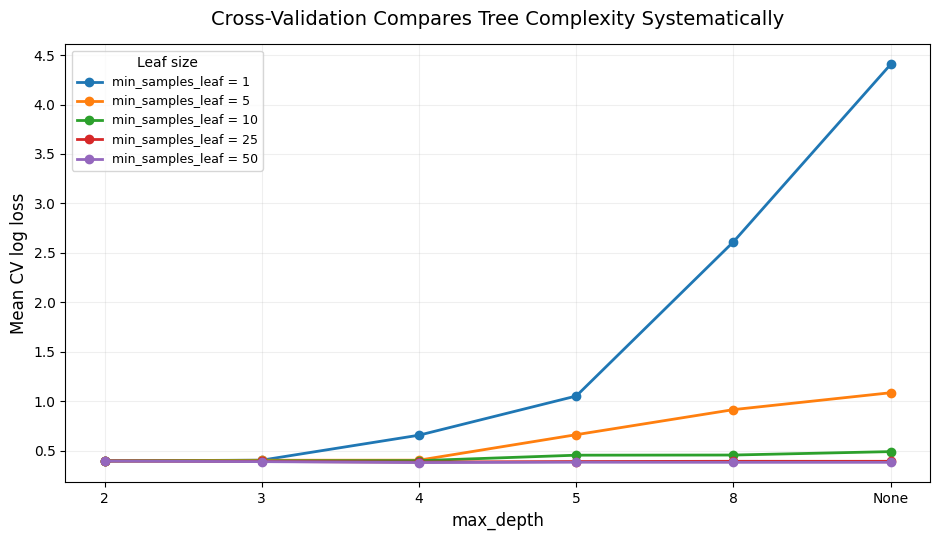

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, log_loss


# ============================================================
# DEMO PLAN 7
# GridSearchCV: Systematic Hyperparameter Selection
# ============================================================


# ------------------------------------------------------------
# 1. Cross-validation setup
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ------------------------------------------------------------
# 2. Moderate hyperparameter grid
# ------------------------------------------------------------

param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, 8, None],
    "min_samples_leaf": [1, 5, 10, 25, 50],
    "ccp_alpha": [0.0, 0.001, 0.005]
}


# ------------------------------------------------------------
# 3. Run GridSearchCV
#
# neg_log_loss is used because sklearn assumes
# "higher score = better."
#
# Therefore:
#     mean_test_score = negative log loss
#
# We convert it back to positive log loss below.
# ------------------------------------------------------------

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    param_grid=param_grid,
    scoring="neg_log_loss",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

grid_search.fit(
    X_train_tree,
    y_train
)


# ------------------------------------------------------------
# 4. Best hyperparameters and best CV score
# ------------------------------------------------------------

best_cv_log_loss = -grid_search.best_score_

print("Best hyperparameters:")
display(
    pd.DataFrame(
        [grid_search.best_params_]
    )
)

print(
    f"Best mean CV log loss: "
    f"{best_cv_log_loss:.3f}"
)


# ------------------------------------------------------------
# 5. Final evaluation
#
# GridSearchCV has already refit the best tree on
# the full training set.
# ------------------------------------------------------------

best_tree = grid_search.best_estimator_

train_pred = best_tree.predict(
    X_train_tree
)

test_pred = best_tree.predict(
    X_test_tree
)

train_prob = best_tree.predict_proba(
    X_train_tree
)[:, 1]

test_prob = best_tree.predict_proba(
    X_test_tree
)[:, 1]


final_performance = pd.DataFrame({
    "dataset": [
        "Training",
        "Holdout test"
    ],
    "accuracy": [
        accuracy_score(
            y_train,
            train_pred
        ),
        accuracy_score(
            y_test,
            test_pred
        )
    ],
    "log loss": [
        log_loss(
            y_train,
            train_prob
        ),
        log_loss(
            y_test,
            test_prob
        )
    ]
})

final_performance[
    ["accuracy", "log loss"]
] = final_performance[
    ["accuracy", "log loss"]
].round(3)

print("\nFinal performance:")
display(final_performance)


# ------------------------------------------------------------
# 6. Top-10 cross-validation results
# ------------------------------------------------------------

results = pd.DataFrame(
    grid_search.cv_results_
)

results["mean CV log loss"] = (
    -results["mean_test_score"]
)

results["SD CV log loss"] = (
    results["std_test_score"]
)

results["mean train log loss"] = (
    -results["mean_train_score"]
)


top_10 = (
    results[
        [
            "param_criterion",
            "param_max_depth",
            "param_min_samples_leaf",
            "param_ccp_alpha",
            "mean CV log loss",
            "SD CV log loss",
            "mean train log loss"
        ]
    ]
    .sort_values(
        "mean CV log loss"
    )
    .head(10)
    .reset_index(drop=True)
)

top_10.index = (
    top_10.index + 1
)

top_10.index.name = "rank"

for column in [
    "mean CV log loss",
    "SD CV log loss",
    "mean train log loss"
]:
    top_10[column] = (
        top_10[column].round(3)
    )

print("\nTop 10 hyperparameter settings:")
display(top_10)


# ------------------------------------------------------------
# 7. Plot:
# mean validation log loss versus max_depth
#
# To keep the figure readable, fix:
#   criterion = the best criterion
#   ccp_alpha = the best ccp_alpha
#
# Then show one line for each min_samples_leaf.
# ------------------------------------------------------------

best_criterion = (
    grid_search.best_params_["criterion"]
)

best_ccp_alpha = (
    grid_search.best_params_["ccp_alpha"]
)


plot_data = results[
    (
        results["param_criterion"]
        == best_criterion
    )
    &
    (
        results["param_ccp_alpha"]
        == best_ccp_alpha
    )
].copy()


# Convert None into a readable label.
plot_data["depth_label"] = (
    plot_data["param_max_depth"]
    .astype(object)
)

plot_data["depth_label"] = (
    plot_data["depth_label"]
    .where(
        plot_data["depth_label"].notna(),
        "None"
    )
)


depth_order = [
    2, 3, 4, 5, 8, "None"
]

x_positions = np.arange(
    len(depth_order)
)


fig, ax = plt.subplots(
    figsize=(9.5, 5.5)
)


for min_leaf in [
    1, 5, 10, 25, 50
]:

    subset = plot_data[
        plot_data[
            "param_min_samples_leaf"
        ] == min_leaf
    ].copy()

    # Put rows in the desired x-axis order.
    subset["depth_order"] = (
        subset["depth_label"]
        .apply(
            lambda x:
            depth_order.index(x)
        )
    )

    subset = subset.sort_values(
        "depth_order"
    )

    ax.plot(
        x_positions,
        subset["mean CV log loss"],
        marker="o",
        linewidth=2,
        label=f"min_samples_leaf = {min_leaf}"
    )


ax.set_xticks(
    x_positions
)

ax.set_xticklabels(
    [
        "2",
        "3",
        "4",
        "5",
        "8",
        "None"
    ]
)

ax.set_xlabel(
    "max_depth",
    fontsize=12
)

ax.set_ylabel(
    "Mean CV log loss",
    fontsize=12
)

ax.set_title(
    "Cross-Validation Compares Tree Complexity Systematically",
    fontsize=14,
    pad=14
)

ax.legend(
    title="Leaf size",
    fontsize=9
)

ax.grid(
    alpha=0.20
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Short warning
# ------------------------------------------------------------

print(
    "\nWarning: The holdout test set should not be used "
    "to choose hyperparameters. It is used only after "
    "model selection to estimate final performance."
)

# 8. Bagging: Many Unstable Trees Become One Stable Model

## Decision trees are high-variance models. Small changes in the training data can produce different splits, especially near the top of the tree.

## Bagging, short for bootstrap aggregation, reduces this instability.

## The bagging recipe:

## 1. Draw a bootstrap sample from the training data.
## 2. Fit a decision tree to that bootstrap sample.
## 3. Repeat many times.
## 4. Average the predicted probabilities or use majority vote.

## A bootstrap sample has the same size as the original training set, but it is sampled with replacement. Some rows appear multiple times. Some rows are left out.

## The left-out rows for a particular tree are called out-of-bag observations. Since that tree did not train on those rows, they can be used as a built-in validation set for that tree.

## Bagging mainly reduces variance. It does not magically fix bias. If every individual tree is missing the same important signal, averaging them will not create that signal.

## For classification, bagging can be understood as probability averaging:

## `P_ensemble(churn) = average of P_tree_j(churn) across all trees`

## This usually produces smoother, less extreme probabilities than a single fully grown tree.

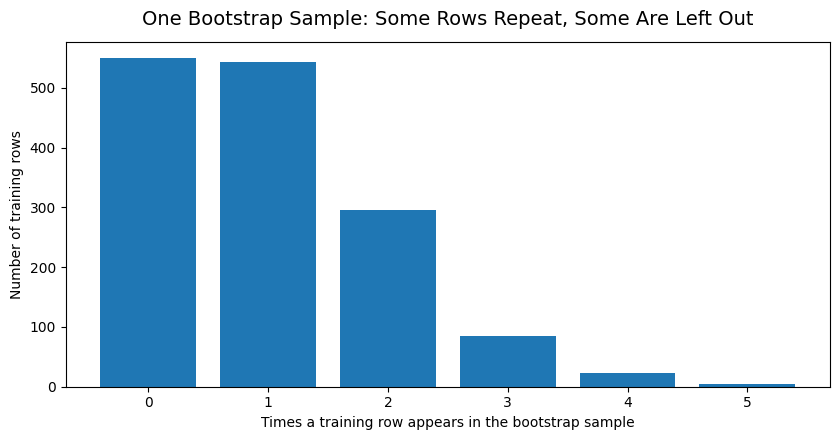

,Quantity,Value
0,Training rows,1500.000
1,Average unique rows per bootstrap sample,947.720
2,Average unique fraction,0.632
3,Average out-of-bag rows per tree,552.280
4,Average out-of-bag fraction,0.368


,model,train log loss,test log loss,train accuracy,test accuracy
0,Single fully-grown tree,0.000,9.011,1.000,0.75
1,Bagging: 50 trees,0.094,0.972,0.999,0.83


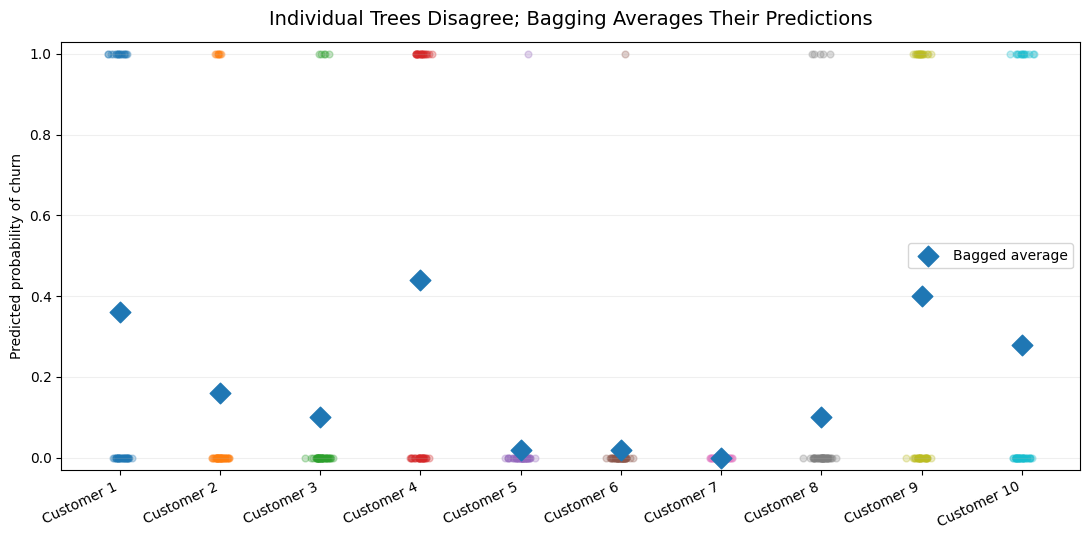

HTML(value='<h3>Interactive: Add More Trees</h3><p>As more trees are averaged, ensemble performance usually be…

SelectionSlider(continuous_update=False, description='Trees:', index=4, layout=Layout(width='500px'), options=…

Output()

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import log_loss, accuracy_score


# ============================================================
# DEMO PLAN 8
# Bagging: Many Unstable Trees Become One Stable Model
# ============================================================

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

y_train_array = np.asarray(y_train)
y_test_array = np.asarray(y_test)

n_train = len(y_train_array)
n_test = len(y_test_array)

N_TREES_TOTAL = 100
N_TREES_MAIN = 50


# ------------------------------------------------------------
# Helper: return P(churn = 1)
# ------------------------------------------------------------

def churn_probability(model, X):
    probabilities = model.predict_proba(X)

    churn_column = np.where(
        model.classes_ == 1
    )[0][0]

    return probabilities[:, churn_column]


# ------------------------------------------------------------
# 1. Manually create bootstrap samples and fit trees
# ------------------------------------------------------------

train_tree_probabilities = []
test_tree_probabilities = []

unique_counts = []
oob_counts = []

first_bootstrap_indices = None


for tree_number in range(N_TREES_TOTAL):

    # Sample n rows WITH replacement.
    bootstrap_indices = rng.choice(
        n_train,
        size=n_train,
        replace=True
    )

    if tree_number == 0:
        first_bootstrap_indices = bootstrap_indices.copy()

    unique_indices = np.unique(
        bootstrap_indices
    )

    unique_counts.append(
        len(unique_indices)
    )

    oob_counts.append(
        n_train - len(unique_indices)
    )

    tree = DecisionTreeClassifier(
        random_state=RANDOM_STATE + tree_number
    )

    tree.fit(
        X_train_tree[bootstrap_indices],
        y_train_array[bootstrap_indices]
    )

    train_tree_probabilities.append(
        churn_probability(
            tree,
            X_train_tree
        )
    )

    test_tree_probabilities.append(
        churn_probability(
            tree,
            X_test_tree
        )
    )


train_tree_probabilities = np.array(
    train_tree_probabilities
)

test_tree_probabilities = np.array(
    test_tree_probabilities
)


# ============================================================
# 2. What does one bootstrap sample look like?
# ============================================================

times_selected = np.bincount(
    first_bootstrap_indices,
    minlength=n_train
)

fig, ax = plt.subplots(
    figsize=(8.5, 4.5)
)

possible_counts = np.arange(
    times_selected.max() + 1
)

frequency = [
    np.sum(times_selected == count)
    for count in possible_counts
]

ax.bar(
    possible_counts,
    frequency
)

ax.set_xlabel(
    "Times a training row appears in the bootstrap sample"
)

ax.set_ylabel(
    "Number of training rows"
)

ax.set_title(
    "One Bootstrap Sample: Some Rows Repeat, Some Are Left Out",
    fontsize=14,
    pad=12
)

ax.set_xticks(
    possible_counts
)

plt.tight_layout()
plt.show()


bootstrap_summary = pd.DataFrame({
    "Quantity": [
        "Training rows",
        "Average unique rows per bootstrap sample",
        "Average unique fraction",
        "Average out-of-bag rows per tree",
        "Average out-of-bag fraction"
    ],
    "Value": [
        n_train,
        np.mean(unique_counts),
        np.mean(unique_counts) / n_train,
        np.mean(oob_counts),
        np.mean(oob_counts) / n_train
    ]
})

bootstrap_summary["Value"] = (
    bootstrap_summary["Value"].round(3)
)

display(bootstrap_summary)


# ============================================================
# 3. Single fully-grown tree versus 50-tree bagging
# ============================================================

single_tree = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

single_tree.fit(
    X_train_tree,
    y_train_array
)

single_train_prob = churn_probability(
    single_tree,
    X_train_tree
)

single_test_prob = churn_probability(
    single_tree,
    X_test_tree
)


# Bagging = average the probabilities from individual trees.
bagged_train_prob = (
    train_tree_probabilities[:N_TREES_MAIN]
    .mean(axis=0)
)

bagged_test_prob = (
    test_tree_probabilities[:N_TREES_MAIN]
    .mean(axis=0)
)


def hard_predictions(probabilities):
    return (
        probabilities >= 0.50
    ).astype(int)


comparison = pd.DataFrame({
    "model": [
        "Single fully-grown tree",
        "Bagging: 50 trees"
    ],

    "train log loss": [
        log_loss(
            y_train_array,
            single_train_prob
        ),
        log_loss(
            y_train_array,
            bagged_train_prob
        )
    ],

    "test log loss": [
        log_loss(
            y_test_array,
            single_test_prob
        ),
        log_loss(
            y_test_array,
            bagged_test_prob
        )
    ],

    "train accuracy": [
        accuracy_score(
            y_train_array,
            hard_predictions(single_train_prob)
        ),
        accuracy_score(
            y_train_array,
            hard_predictions(bagged_train_prob)
        )
    ],

    "test accuracy": [
        accuracy_score(
            y_test_array,
            hard_predictions(single_test_prob)
        ),
        accuracy_score(
            y_test_array,
            hard_predictions(bagged_test_prob)
        )
    ]
})

comparison[
    [
        "train log loss",
        "test log loss",
        "train accuracy",
        "test accuracy"
    ]
] = comparison[
    [
        "train log loss",
        "test log loss",
        "train accuracy",
        "test accuracy"
    ]
].round(3)

display(comparison)


# ============================================================
# 4. Ten test customers:
# individual trees disagree, bagging averages them
# ============================================================

# Choose evenly spaced test observations so the example is reproducible.
selected_customers = np.linspace(
    0,
    n_test - 1,
    10,
    dtype=int
)

selected_tree_probs = (
    test_tree_probabilities[
        :N_TREES_MAIN,
        selected_customers
    ]
)

selected_bagged_probs = (
    selected_tree_probs.mean(axis=0)
)


fig, ax = plt.subplots(
    figsize=(11, 5.5)
)

customer_positions = np.arange(1, 11)

jitter_rng = np.random.default_rng(123)


# Plot one point per tree for each customer.
for customer_index, x_position in enumerate(customer_positions):

    x_jitter = (
        x_position
        + jitter_rng.normal(
            0,
            0.055,
            N_TREES_MAIN
        )
    )

    ax.scatter(
        x_jitter,
        selected_tree_probs[:, customer_index],
        alpha=0.28,
        s=24
    )


# Overlay the bagged average.
ax.scatter(
    customer_positions,
    selected_bagged_probs,
    marker="D",
    s=110,
    label="Bagged average",
    zorder=5
)

ax.set_xticks(
    customer_positions
)

ax.set_xticklabels(
    [
        f"Customer {i}"
        for i in range(1, 11)
    ],
    rotation=25,
    ha="right"
)

ax.set_ylim(
    -0.03,
    1.03
)

ax.set_ylabel(
    "Predicted probability of churn"
)

ax.set_title(
    "Individual Trees Disagree; Bagging Averages Their Predictions",
    fontsize=14,
    pad=12
)

ax.legend()
ax.grid(
    axis="y",
    alpha=0.20
)

plt.tight_layout()
plt.show()


# ============================================================
# 5. OPTIONAL INTERACTIVE VERSION
# How does performance stabilize as trees are added?
# ============================================================

tree_count_slider = widgets.SelectionSlider(
    options=[1, 5, 10, 25, 50, 100],
    value=50,
    description="Trees:",
    continuous_update=False,
    style={"description_width": "60px"},
    layout=widgets.Layout(width="500px")
)

bagging_output = widgets.Output()


def update_bagging(change=None):

    n_trees = tree_count_slider.value

    ensemble_test_prob = (
        test_tree_probabilities[:n_trees]
        .mean(axis=0)
    )

    ensemble_test_pred = hard_predictions(
        ensemble_test_prob
    )

    test_loss = log_loss(
        y_test_array,
        ensemble_test_prob
    )

    test_acc = accuracy_score(
        y_test_array,
        ensemble_test_pred
    )

    metrics = pd.DataFrame({
        "number of trees": [n_trees],
        "test log loss": [test_loss],
        "test accuracy": [test_acc]
    }).round(3)

    with bagging_output:

        clear_output(wait=True)

        fig, ax = plt.subplots(
            figsize=(8.5, 4.5)
        )

        ax.hist(
            ensemble_test_prob,
            bins=np.linspace(0, 1, 21),
            edgecolor="black"
        )

        ax.set_xlim(
            0,
            1
        )

        ax.set_xlabel(
            "Bagged predicted probability of churn"
        )

        ax.set_ylabel(
            "Number of test customers"
        )

        ax.set_title(
            f"Predictions Using {n_trees} Tree"
            + ("" if n_trees == 1 else "s"),
            fontsize=14,
            pad=12
        )

        plt.tight_layout()
        plt.show()

        display(metrics)


tree_count_slider.observe(
    update_bagging,
    names="value"
)

display(
    widgets.HTML(
        "<h3>Interactive: Add More Trees</h3>"
        "<p>As more trees are averaged, ensemble performance "
        "usually becomes more stable.</p>"
    ),
    tree_count_slider,
    bagging_output
)

update_bagging()

# 9. Random Forests: Bagging Plus Feature Randomness

## A random forest is bagging with one extra source of randomness.

## Bagging randomizes the rows by using bootstrap samples.

## Random forests also randomize the columns: at each split, a tree is allowed to consider only a random subset of features.

## This matters because bagged trees can still be highly correlated. If one feature is very strong, many trees may use that same feature near the top. Then the trees become similar, and averaging similar trees gives less benefit.

## Feature subsampling decorrelates the trees. It forces different trees to explore different predictors and interactions.

## The standard random forest idea:

## - many trees
## - bootstrap samples of rows
## - random subset of features at each split
## - average probabilities or majority vote

## Key hyperparameters:

## - `n_estimators`: number of trees
## - `max_features`: number of features considered at each split
## - `max_depth`: maximum tree depth
## - `min_samples_leaf`: minimum samples per leaf
## - `min_samples_split`: minimum samples needed to split a node
## - `bootstrap`: whether to use bootstrap samples

## Random forests often perform well with less tuning than single trees. But they are not automatically perfect. They can still overfit, especially with noisy labels, small datasets, or poorly chosen hyperparameters.

,model,trees,max features,train log loss,test log loss,train accuracy,test accuracy,test recall (churn),test precision (churn)
0,Single decision tree,1,All,0.000,9.011,1.0,0.750,0.321,0.258
1,Bagged trees,100,All,0.093,0.526,1.0,0.836,0.192,0.441
2,Random forest,100,sqrt,0.091,0.581,1.0,0.842,0.179,0.483


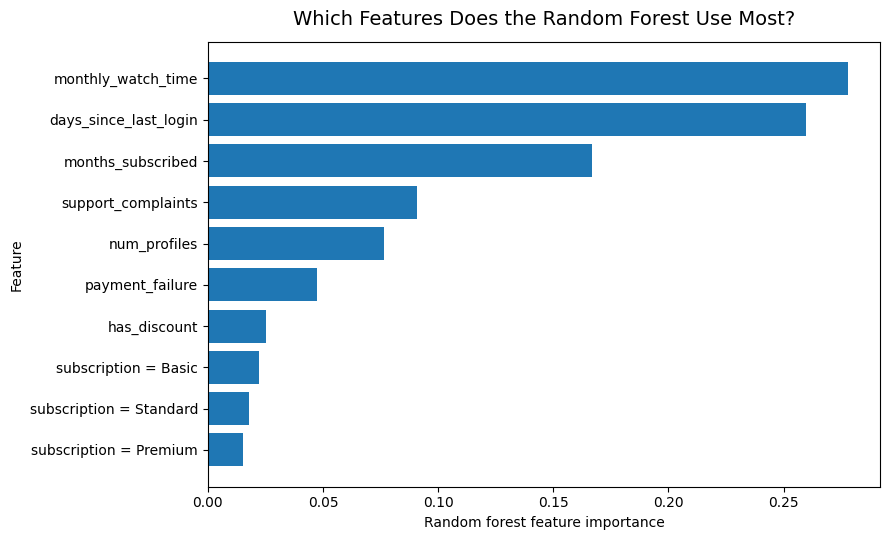

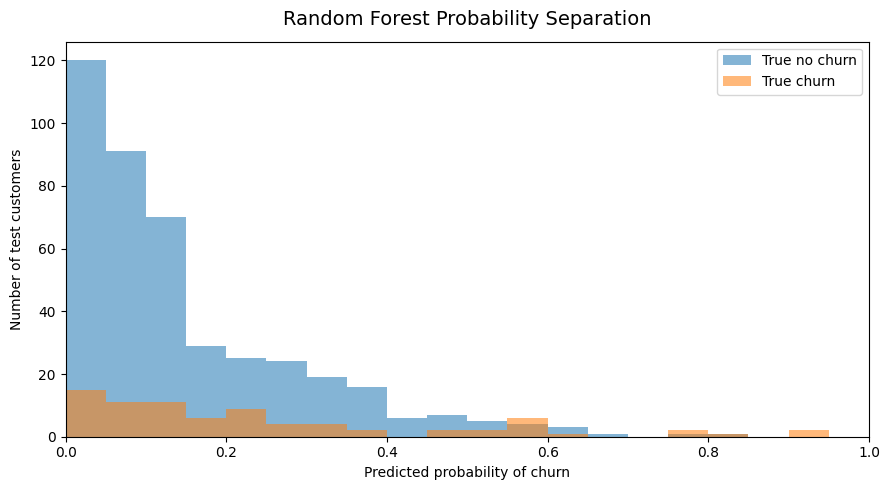

HTML(value='<h3>Interactive: Feature Randomness in a Random Forest</h3><p>Compare <b>sqrt</b> with <b>All feat…

Output()

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.metrics import (
    log_loss,
    accuracy_score,
    recall_score,
    precision_score
)


# ============================================================
# DEMO PLAN 9
# Random Forests: Bagging Plus Feature Randomness
# ============================================================

RANDOM_STATE = 42
N_TREES = 100

y_train_array = np.asarray(y_train)
y_test_array = np.asarray(y_test)


# ------------------------------------------------------------
# Helper: probability of churn
# ------------------------------------------------------------

def p_churn(model, X):
    probabilities = model.predict_proba(X)
    churn_column = np.where(model.classes_ == 1)[0][0]
    return probabilities[:, churn_column]


# ============================================================
# 1. Fit three comparable models
# ============================================================

single_tree_rf_demo = DecisionTreeClassifier(
    max_depth=None,
    min_samples_leaf=1,
    random_state=RANDOM_STATE
)


bagged_trees = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=None,
        min_samples_leaf=1
    ),
    n_estimators=N_TREES,
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)


random_forest = RandomForestClassifier(
    n_estimators=N_TREES,
    max_features="sqrt",
    max_depth=None,
    min_samples_leaf=1,
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)


models = [
    (
        "Single decision tree",
        single_tree_rf_demo,
        1,
        "All"
    ),
    (
        "Bagged trees",
        bagged_trees,
        N_TREES,
        "All"
    ),
    (
        "Random forest",
        random_forest,
        N_TREES,
        "sqrt"
    )
]


for _, model, _, _ in models:
    model.fit(
        X_train_tree,
        y_train_array
    )


# ============================================================
# 2. Compact comparison table
# ============================================================

comparison_rows = []

for model_name, model, n_trees, max_features in models:

    train_probability = p_churn(
        model,
        X_train_tree
    )

    test_probability = p_churn(
        model,
        X_test_tree
    )

    train_prediction = (
        train_probability >= 0.50
    ).astype(int)

    test_prediction = (
        test_probability >= 0.50
    ).astype(int)

    comparison_rows.append({
        "model": model_name,
        "trees": n_trees,
        "max features": max_features,

        "train log loss": log_loss(
            y_train_array,
            train_probability
        ),

        "test log loss": log_loss(
            y_test_array,
            test_probability
        ),

        "train accuracy": accuracy_score(
            y_train_array,
            train_prediction
        ),

        "test accuracy": accuracy_score(
            y_test_array,
            test_prediction
        ),

        "test recall (churn)": recall_score(
            y_test_array,
            test_prediction
        ),

        "test precision (churn)": precision_score(
            y_test_array,
            test_prediction,
            zero_division=0
        )
    })


comparison_rf = pd.DataFrame(
    comparison_rows
)


metric_columns = [
    "train log loss",
    "test log loss",
    "train accuracy",
    "test accuracy",
    "test recall (churn)",
    "test precision (churn)"
]

comparison_rf[metric_columns] = (
    comparison_rf[metric_columns].round(3)
)

display(comparison_rf)


# ============================================================
# 3. Random-forest feature importance
# ============================================================

# feature_names was created in Demo Plan 2.
# If it is not currently available, rebuild it from the
# fitted preprocessor.

try:
    importance_feature_names = list(feature_names)

except NameError:

    importance_feature_names = (
        preprocessor.get_feature_names_out()
    )

    importance_feature_names = [
        name
        .replace(
            "cat__subscription_type_",
            "subscription = "
        )
        .replace(
            "num__",
            ""
        )
        for name in importance_feature_names
    ]


importance_df = pd.DataFrame({
    "feature": importance_feature_names,
    "importance": random_forest.feature_importances_
})

importance_df = (
    importance_df
    .sort_values(
        "importance",
        ascending=True
    )
)


fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

ax.barh(
    importance_df["feature"],
    importance_df["importance"]
)

ax.set_xlabel(
    "Random forest feature importance"
)

ax.set_ylabel(
    "Feature"
)

ax.set_title(
    "Which Features Does the Random Forest Use Most?",
    fontsize=14,
    pad=12
)

plt.tight_layout()
plt.show()


# ============================================================
# 4. Probability distributions on the TEST set
# ============================================================

rf_test_probability = p_churn(
    random_forest,
    X_test_tree
)

prob_no_churn = rf_test_probability[
    y_test_array == 0
]

prob_churn = rf_test_probability[
    y_test_array == 1
]


bins = np.linspace(
    0,
    1,
    21
)


fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.hist(
    prob_no_churn,
    bins=bins,
    alpha=0.55,
    label="True no churn"
)

ax.hist(
    prob_churn,
    bins=bins,
    alpha=0.55,
    label="True churn"
)

ax.set_xlim(
    0,
    1
)

ax.set_xlabel(
    "Predicted probability of churn"
)

ax.set_ylabel(
    "Number of test customers"
)

ax.set_title(
    "Random Forest Probability Separation",
    fontsize=14,
    pad=12
)

ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 5. OPTIONAL INTERACTIVE VERSION
#
# Keep the controls focused:
#   - number of trees
#   - max_features
#
# These directly illustrate the main random-forest idea.
# ============================================================

n_estimators_control = widgets.SelectionSlider(
    options=[10, 25, 50, 100, 200],
    value=100,
    description="Trees:",
    continuous_update=False,
    style={"description_width": "90px"},
    layout=widgets.Layout(width="500px")
)


max_features_control = widgets.Dropdown(
    options=[
        ("sqrt", "sqrt"),
        ("log2", "log2"),
        ("All features", None)
    ],
    value="sqrt",
    description="Max features:",
    style={"description_width": "90px"},
    layout=widgets.Layout(width="300px")
)


rf_output = widgets.Output()


def update_random_forest(change=None):

    n_estimators = (
        n_estimators_control.value
    )

    max_features = (
        max_features_control.value
    )


    interactive_rf = RandomForestClassifier(
        n_estimators=n_estimators,
        max_features=max_features,
        max_depth=None,
        min_samples_leaf=1,
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    interactive_rf.fit(
        X_train_tree,
        y_train_array
    )


    test_probability = p_churn(
        interactive_rf,
        X_test_tree
    )

    test_prediction = (
        test_probability >= 0.50
    ).astype(int)


    metrics = pd.DataFrame({
        "trees": [
            n_estimators
        ],

        "max_features": [
            "All"
            if max_features is None
            else max_features
        ],

        "test log loss": [
            log_loss(
                y_test_array,
                test_probability
            )
        ],

        "test accuracy": [
            accuracy_score(
                y_test_array,
                test_prediction
            )
        ],

        "churn recall": [
            recall_score(
                y_test_array,
                test_prediction
            )
        ]
    })


    metrics[
        [
            "test log loss",
            "test accuracy",
            "churn recall"
        ]
    ] = metrics[
        [
            "test log loss",
            "test accuracy",
            "churn recall"
        ]
    ].round(3)


    interactive_importance = pd.DataFrame({
        "feature":
            importance_feature_names,

        "importance":
            interactive_rf.feature_importances_
    })

    interactive_importance = (
        interactive_importance
        .sort_values(
            "importance",
            ascending=True
        )
    )


    with rf_output:

        clear_output(
            wait=True
        )

        display(metrics)

        fig, ax = plt.subplots(
            figsize=(8.5, 5)
        )

        ax.barh(
            interactive_importance["feature"],
            interactive_importance["importance"]
        )

        ax.set_xlabel(
            "Feature importance"
        )

        ax.set_title(
            f"Random Forest: "
            f"{n_estimators} Trees, "
            f"max_features="
            f"{'All' if max_features is None else max_features}",
            fontsize=13,
            pad=12
        )

        plt.tight_layout()
        plt.show()


n_estimators_control.observe(
    update_random_forest,
    names="value"
)

max_features_control.observe(
    update_random_forest,
    names="value"
)


display(
    widgets.HTML(
        "<h3>Interactive: Feature Randomness in a Random Forest</h3>"
        "<p>Compare <b>sqrt</b> with <b>All features</b>. "
        "Using all features makes the model more like ordinary bagging.</p>"
    ),

    widgets.HBox([
        n_estimators_control,
        max_features_control
    ]),

    rf_output
)

update_random_forest()

# 10. Feature Importance: Useful, But Not Causal

## Random forests provide feature importances, but you should interpret them carefully.

## The common impurity-based importance measures how much a feature reduces impurity across the forest. If a feature is often used for strong splits, it receives high importance.

## This does not mean:

## - the feature causes churn
## - changing the feature would change churn
## - the feature is always the most important in a business sense
## - the importance is unbiased

## Impurity-based importance can favor continuous variables or variables with many possible split points. It can also spread importance across correlated features.

## For example, `days_since_last_login` and `monthly_watch_time` may both measure engagement. If both are included, importance may be divided between them. If one is removed, the other may become more important.

,feature,impurity importance,permutation importance,permutation SD
0,payment_failure,0.0473,0.0174,0.0154
1,has_discount,0.0254,-0.0048,0.0684
2,num_profiles,0.0765,-0.0052,0.0644
3,days_since_last_login,0.2596,-0.0135,0.0673
4,months_subscribed,0.1670,-0.0179,0.0597
5,subscription_type,0.0553,-0.0387,0.0650
6,support_complaints,0.0908,-0.0560,0.0583
7,monthly_watch_time,0.2780,-0.0701,0.0563


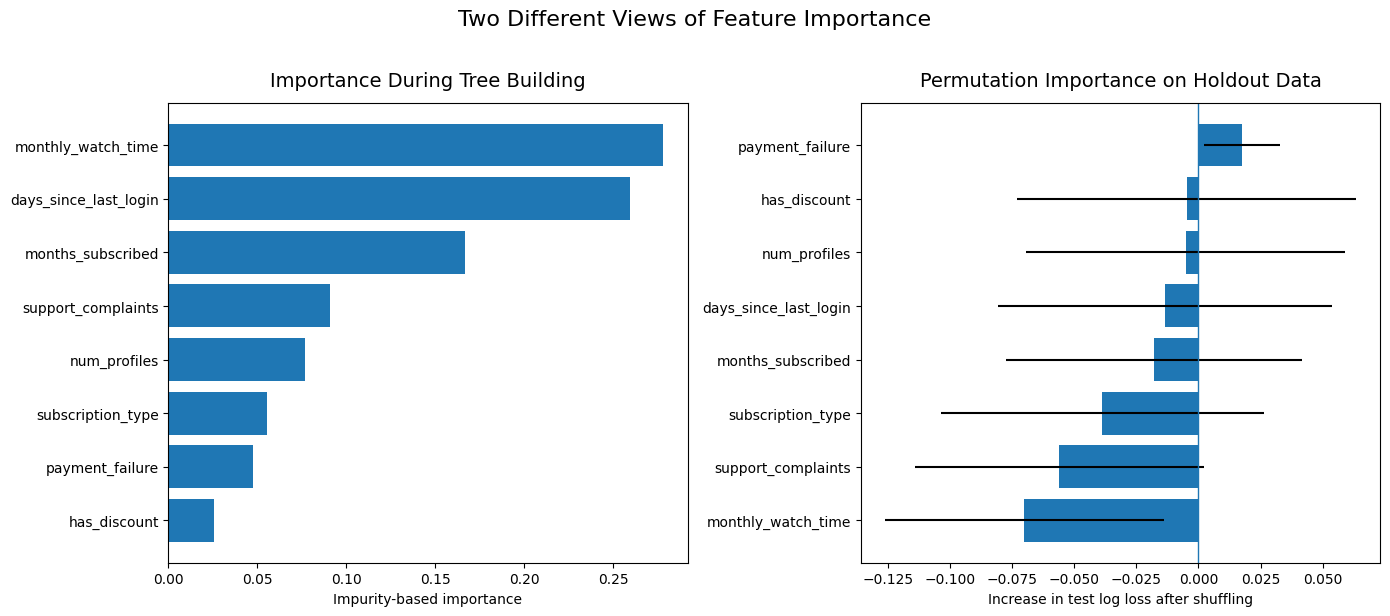

,feature,impurity rank,permutation rank,impurity importance,permutation importance
0,payment_failure,7,1,0.0473,0.0174
1,has_discount,8,2,0.0254,-0.0048
2,num_profiles,5,3,0.0765,-0.0052
3,days_since_last_login,2,4,0.2596,-0.0135
4,months_subscribed,3,5,0.1670,-0.0179
5,subscription_type,6,6,0.0553,-0.0387
6,support_complaints,4,7,0.0908,-0.0560
7,monthly_watch_time,1,8,0.2780,-0.0701


Baseline random-forest test log loss: 0.581

Interpretation: larger permutation importance means test log loss increased more when that feature was shuffled.
Importance does NOT imply that changing the feature would cause churn to change.


In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import log_loss


# ============================================================
# DEMO PLAN 10
# Feature Importance and Permutation Importance
# ============================================================

RANDOM_STATE = 42


# ------------------------------------------------------------
# 1. Fit the final random forest as a pipeline
#
# This lets permutation importance shuffle ORIGINAL features
# such as "subscription_type", rather than individual
# one-hot-encoded columns.
# ------------------------------------------------------------

final_rf_pipeline = Pipeline([
    (
        "preprocess",
        clone(preprocessor)
    ),
    (
        "forest",
        RandomForestClassifier(
            n_estimators=100,
            max_features="sqrt",
            max_depth=None,
            min_samples_leaf=1,
            bootstrap=True,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
])

final_rf_pipeline.fit(
    X_train,
    y_train
)

forest = final_rf_pipeline.named_steps["forest"]
fitted_preprocessor = final_rf_pipeline.named_steps["preprocess"]


# ------------------------------------------------------------
# 2. Impurity-based importance
#
# The forest sees one-hot-encoded columns, so aggregate those
# columns back to the original feature names.
# ------------------------------------------------------------

transformed_names = (
    fitted_preprocessor.get_feature_names_out()
)

transformed_importance = pd.DataFrame({
    "transformed_feature": transformed_names,
    "importance": forest.feature_importances_
})


def original_feature_name(name):

    # Categorical one-hot columns
    if name.startswith("cat__subscription_type_"):
        return "subscription_type"

    # Numeric columns
    if name.startswith("num__"):
        return name.replace("num__", "")

    return name


transformed_importance["feature"] = (
    transformed_importance[
        "transformed_feature"
    ].apply(original_feature_name)
)


impurity_importance = (
    transformed_importance
    .groupby("feature", as_index=False)["importance"]
    .sum()
)

impurity_importance = impurity_importance.rename(
    columns={
        "importance": "impurity importance"
    }
)


# ------------------------------------------------------------
# 3. Permutation importance on the HOLDOUT TEST SET
#
# scoring="neg_log_loss" means:
#
# importance =
#     test log loss after shuffling
#     minus
#     original test log loss
#
# So a larger positive number means performance got worse
# when that feature was destroyed.
# ------------------------------------------------------------

permutation = permutation_importance(
    final_rf_pipeline,
    X_test,
    y_test,
    scoring="neg_log_loss",
    n_repeats=20,
    random_state=RANDOM_STATE,
    n_jobs=-1
)


permutation_df = pd.DataFrame({
    "feature": X_test.columns,
    "permutation importance": permutation.importances_mean,
    "permutation SD": permutation.importances_std
})


# ------------------------------------------------------------
# 4. Combine the two measures
# ------------------------------------------------------------

importance_comparison = (
    impurity_importance
    .merge(
        permutation_df,
        on="feature"
    )
)

importance_comparison = (
    importance_comparison
    .sort_values(
        "permutation importance",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    importance_comparison.round(4)
)


# ------------------------------------------------------------
# 5. Side-by-side plots
# ------------------------------------------------------------

impurity_plot = (
    importance_comparison
    .sort_values(
        "impurity importance",
        ascending=True
    )
)

permutation_plot = (
    importance_comparison
    .sort_values(
        "permutation importance",
        ascending=True
    )
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)


# Impurity importance
axes[0].barh(
    impurity_plot["feature"],
    impurity_plot["impurity importance"]
)

axes[0].set_xlabel(
    "Impurity-based importance"
)

axes[0].set_title(
    "Importance During Tree Building",
    fontsize=14,
    pad=12
)


# Permutation importance
axes[1].barh(
    permutation_plot["feature"],
    permutation_plot["permutation importance"],
    xerr=permutation_plot["permutation SD"]
)

axes[1].axvline(
    0,
    linewidth=1
)

axes[1].set_xlabel(
    "Increase in test log loss after shuffling"
)

axes[1].set_title(
    "Permutation Importance on Holdout Data",
    fontsize=14,
    pad=12
)


fig.suptitle(
    "Two Different Views of Feature Importance",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Compact comparison of rankings
# ------------------------------------------------------------

ranking_table = importance_comparison[
    [
        "feature",
        "impurity importance",
        "permutation importance"
    ]
].copy()


ranking_table["impurity rank"] = (
    ranking_table[
        "impurity importance"
    ]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

ranking_table["permutation rank"] = (
    ranking_table[
        "permutation importance"
    ]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

ranking_table = ranking_table[
    [
        "feature",
        "impurity rank",
        "permutation rank",
        "impurity importance",
        "permutation importance"
    ]
].sort_values(
    "permutation rank"
)

display(
    ranking_table.round(4)
)


# ------------------------------------------------------------
# 7. Confirm the baseline probability performance
# ------------------------------------------------------------

test_probability = final_rf_pipeline.predict_proba(
    X_test
)[:, 1]

print(
    "Baseline random-forest test log loss:",
    round(
        log_loss(
            y_test,
            test_probability
        ),
        3
    )
)

print(
    "\nInterpretation: larger permutation importance means "
    "test log loss increased more when that feature was shuffled."
)

print(
    "Importance does NOT imply that changing the feature "
    "would cause churn to change."
)